# Evaluación Sumativa 3. Modelamiento Predictivo Integrado
## Dataset: Give Me Some Credit (riesgo crediticio)

MCDI501: Estadística Computacional para la Toma de Decisiones

Cuaderno que integra las Sumativas 1 y 2. La imputación, la selección de variables, la validación por bootstrap y la lectura de la colinealidad se fundamentan en S1 (faltantes, correlaciones, outliers, códigos 96/98) y S2 (correlaciones validadas, artefacto de atrasos, mediana del ingreso). Semilla 42.

## 0. Configuración y datos

In [1]:
import numpy as np, pandas as pd, warnings
warnings.filterwarnings('ignore')
from scipy import stats
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve,
                             accuracy_score, precision_score, recall_score, f1_score)
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib.pyplot as plt, os
SEED=42; rng=np.random.default_rng(SEED)
INK='#2b2b2b'; TEAL='#2f6b76'; OCHRE='#c0852f'; BRICK='#a4503e'; STEM='#b9b0a2'; PANEL='#f7f3ec'; GRIDC='#ded6c8'
plt.rcParams.update({'figure.dpi':120,'savefig.dpi':200,'font.size':10,'font.family':'serif',
    'figure.facecolor':'white','axes.facecolor':PANEL,'axes.edgecolor':'#9a9486','axes.linewidth':0.8,
    'axes.spines.top':False,'axes.spines.right':False,'axes.titlesize':11,'axes.titlelocation':'left',
    'axes.titlepad':8,'text.color':INK,'axes.labelcolor':INK,'xtick.color':INK,'ytick.color':INK})
def grid_h(ax): ax.set_axisbelow(True); ax.grid(axis='y',color=GRIDC,lw=0.7); ax.grid(axis='x',visible=False)
LOCAL='cs-training.csv'
MIRROR='https://raw.githubusercontent.com/vivekkalyan/give-me-some-credit/master/cs-training.csv'
df = pd.read_csv(LOCAL, index_col=0) if os.path.exists(LOCAL) else pd.read_csv(MIRROR, index_col=0)
TARGET='SeriousDlqin2yrs'
D1='NumberOfTime30-59DaysPastDueNotWorse'; D2='NumberOfTimes90DaysLate'; D3='NumberOfTime60-89DaysPastDueNotWorse'
print('Filas:', len(df))

Filas: 150000


## 1. Manejo inteligente de datos faltantes

### 1.1 Referencia al análisis de faltantes de S1
S1 identificó faltantes solo en el ingreso mensual (29.731; 19,8%) y el número de dependientes (3.924; 2,6%). El patrón del ingreso se trata como MAR: su ausencia se asocia a variables observadas, no al ingreso no observado. Arrastramos de S1 la eliminación de la edad 0, el acotamiento de los códigos 96/98 en atrasos y el recorte al percentil 99 de utilización, ratio de deuda e ingreso.

In [2]:
df=df[df['age']>0].copy()
for c in [D1,D2,D3]: df[c]=df[c].clip(upper=df.loc[df[c]<90,c].max())
for c in ['RevolvingUtilizationOfUnsecuredLines','DebtRatio']: df[c]=df[c].clip(upper=df[c].quantile(0.99))
print('Faltantes -> ingreso:', int(df.MonthlyIncome.isna().sum()), '| dependientes:', int(df.NumberOfDependents.isna().sum()))

Faltantes -> ingreso: 29731 | dependientes: 3924


### 1.2 Imputación mediante regresión lineal múltiple
Los predictores se eligen con las correlaciones de S1 (reproducidas abajo), priorizando las que S2 validó estables. Ajustamos sobre casos completos, verificamos los supuestos con los residuos y documentamos los valores imputados y el encogimiento de varianza propio del método.

In [3]:
comp=df.dropna(subset=['MonthlyIncome','NumberOfDependents'])
pred_inc=['NumberRealEstateLoansOrLines','NumberOfOpenCreditLinesAndLoans','age','DebtRatio']
pred_dep=['age','NumberOfOpenCreditLinesAndLoans','NumberRealEstateLoansOrLines']
print('Correlaciones de S1 que justifican los predictores:')
print('  Ingreso vs     ', {p:round(np.corrcoef(comp.MonthlyIncome,comp[p])[0,1],3) for p in pred_inc})
print('  Dependientes vs', {p:round(np.corrcoef(comp.NumberOfDependents,comp[p])[0,1],3) for p in pred_dep})
lm=LinearRegression().fit(comp[pred_inc], comp['MonthlyIncome'])
lmd=LinearRegression().fit(comp[pred_dep], comp['NumberOfDependents'])
pred=lm.predict(comp[pred_inc]); resid=comp['MonthlyIncome'].values-pred
print(f'\nAjuste ingreso: R2={lm.score(comp[pred_inc],comp.MonthlyIncome):.4f} | dependientes: R2={lmd.score(comp[pred_dep],comp.NumberOfDependents):.4f}')
print('Verificacion de supuestos (regresion del ingreso):')
print(f'  residuos: media={resid.mean():.0f}, sd={resid.std():.0f}, asimetria={stats.skew(resid):.1f}')
print(f'  corr(residuo, ajustado)={np.corrcoef(resid,pred)[0,1]:.3f} -> linealidad en media OK; residuos NO normales')
print(f'  encogimiento: sd(observado)={comp.MonthlyIncome.std():.0f} vs sd(imputado)={pred.std():.0f} ({(1-pred.std()/comp.MonthlyIncome.std())*100:.0f}% menos)')
print(f'  valores imputados: ingreso={int(df.MonthlyIncome.isna().sum())}, dependientes={int(df.NumberOfDependents.isna().sum())}')

Correlaciones de S1 que justifican los predictores:
  Ingreso vs      {'NumberRealEstateLoansOrLines': np.float64(0.125), 'NumberOfOpenCreditLinesAndLoans': np.float64(0.091), 'age': np.float64(0.038), 'DebtRatio': np.float64(-0.043)}
  Dependientes vs {'age': np.float64(-0.206), 'NumberOfOpenCreditLinesAndLoans': np.float64(0.038), 'NumberRealEstateLoansOrLines': np.float64(0.119)}

Ajuste ingreso: R2=0.0201 | dependientes: R2=0.0608
Verificacion de supuestos (regresion del ingreso):
  residuos: media=-0, sd=14239, asimetria=117.4
  corr(residuo, ajustado)=0.000 -> linealidad en media OK; residuos NO normales
  encogimiento: sd(observado)=14385 vs sd(imputado)=2039 (86% menos)
  valores imputados: ingreso=29731, dependientes=3924


#### Figura 1. Imputación: encogimiento de varianza y diagnóstico de residuos

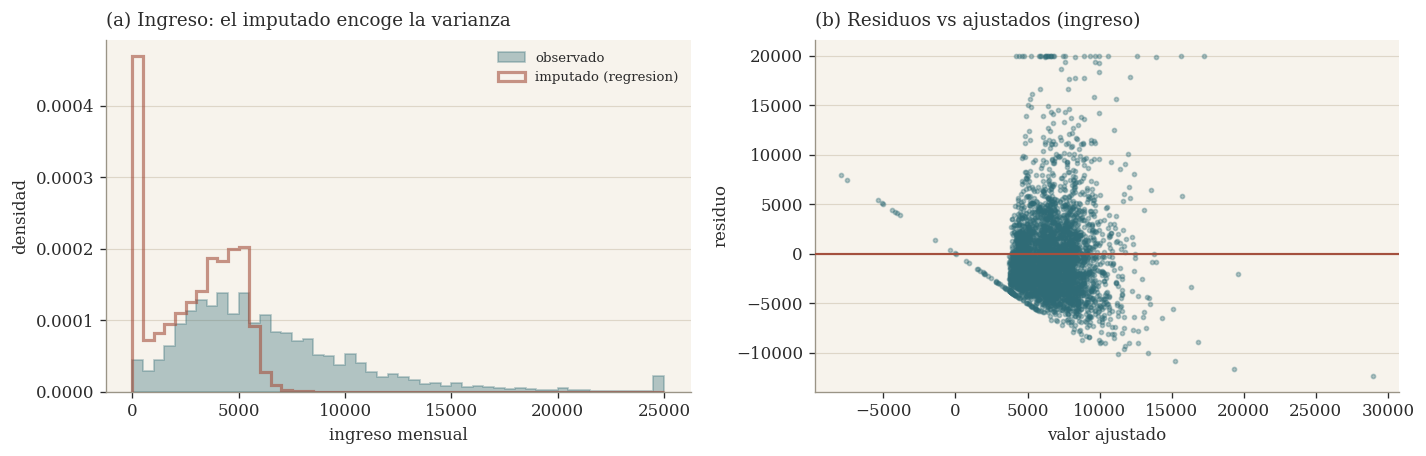

In [4]:
fig,ax=plt.subplots(1,2,figsize=(12,3.9))
obs=comp['MonthlyIncome'].clip(upper=comp['MonthlyIncome'].quantile(0.99))
imp=np.clip(lm.predict(df.loc[df.MonthlyIncome.isna(),pred_inc]),0,obs.quantile(0.99))
ax[0].hist(obs,bins=50,color=TEAL,alpha=0.35,histtype='stepfilled',edgecolor=TEAL,lw=1,density=True,label='observado',zorder=2)
ax[0].hist(imp,bins=50,color=BRICK,alpha=0.6,histtype='step',lw=1.9,density=True,label='imputado (regresion)',zorder=3)
ax[0].set_title('(a) Ingreso: el imputado encoge la varianza'); ax[0].set_xlabel('ingreso mensual'); ax[0].set_ylabel('densidad'); grid_h(ax[0]); ax[0].legend(fontsize=8,frameon=False)
s=rng.choice(len(pred),4000,replace=False)
ax[1].scatter(pred[s],np.clip(resid[s],-2e4,2e4),s=6,color=TEAL,alpha=0.35,zorder=2); ax[1].axhline(0,color=BRICK,lw=1.3,zorder=3)
ax[1].set_title('(b) Residuos vs ajustados (ingreso)'); ax[1].set_xlabel('valor ajustado'); ax[1].set_ylabel('residuo'); grid_h(ax[1])
plt.tight_layout(); plt.savefig('fig_imputacion.png',bbox_inches='tight'); plt.show()

Los residuos tienen media cero y no correlacionan con el ajustado (linealidad en media razonable), pero son muy asimétricos, es decir, la normalidad no se cumple, coherente con la cola larga del ingreso. La limitación más relevante es el encogimiento de varianza: la regresión reemplaza cada faltante por su predicción, y los valores imputados tienen un 86% menos de dispersión que los observados (pico estrecho de la Figura 1a). Esto subestima la variabilidad del ingreso. Lo asumimos como costo conocido del método.

### 1.3 Comparación de estrategias de imputación

In [5]:
df_del=df.dropna(subset=['MonthlyIncome','NumberOfDependents']).copy()
df_simple=df.copy()
df_simple['MonthlyIncome']=df_simple['MonthlyIncome'].fillna(df_simple['MonthlyIncome'].median())
df_simple['NumberOfDependents']=df_simple['NumberOfDependents'].fillna(df_simple['NumberOfDependents'].median())
df_reg=df.copy()
mi=df_reg['MonthlyIncome'].isna(); df_reg.loc[mi,'MonthlyIncome']=np.clip(lm.predict(df_reg.loc[mi,pred_inc]),0,None)
mdp=df_reg['NumberOfDependents'].isna(); df_reg.loc[mdp,'NumberOfDependents']=np.clip(np.round(lmd.predict(df_reg.loc[mdp,pred_dep])),0,None)
for d in [df_del,df_simple,df_reg]: d['MonthlyIncome']=d['MonthlyIncome'].clip(upper=d['MonthlyIncome'].quantile(0.99))
tab=[[nm,len(d),d.MonthlyIncome.mean(),d.MonthlyIncome.median(),d.MonthlyIncome.std(),np.corrcoef(d.MonthlyIncome,d[TARGET])[0,1]]
     for nm,d in [('Eliminacion',df_del),('Imputacion simple',df_simple),('Imputacion regresion',df_reg)]]
print(pd.DataFrame(tab,columns=['Estrategia','n','Media','Mediana','Desv.','corr']).set_index('Estrategia').round(3))

                           n     Media  Mediana     Desv.   corr
Estrategia                                                      
Eliminacion           120268  6349.115   5400.0  4358.394 -0.056
Imputacion simple     149999  6142.446   5400.0  3835.691 -0.050
Imputacion regresion  149999  5634.888   4800.0  4162.029 -0.045


Las tres conservan la mediana cercana a 5.400 y correlación con la morosidad igualmente débil (cerca de -0,05). La eliminación pierde 30.000 casos. Adoptamos la imputación por regresión: conserva el tamaño completo, usa la estructura de S1 y no distorsiona la relación con el objetivo, asumiendo el encogimiento como limitación.

## 2. Clasificación mediante regresión logística

### 2.1 Preparación de datos informada por S1
Partición 70/30 estratificada por el objetivo (desbalance de S1, 6,7%): 104.999 de entrenamiento y 45.000 de prueba. Estandarizamos los predictores (odds ratios por desviación estándar). Los outliers de utilización, ratio de deuda e ingreso se recortaron al percentil 99 como en S1, y los códigos 96/98 de atrasos se acotaron a su máximo legítimo, lo que evita que dominen el ajuste sin descartar casos.

In [6]:
FEATURES=['RevolvingUtilizationOfUnsecuredLines','age',D1,'DebtRatio','MonthlyIncome',
          'NumberOfOpenCreditLinesAndLoans',D2,'NumberRealEstateLoansOrLines',D3,'NumberOfDependents']
short={FEATURES[0]:'Utilizacion',FEATURES[1]:'Edad',FEATURES[2]:'Atrasos30-59',FEATURES[3]:'RatioDeuda',
       FEATURES[4]:'Ingreso',FEATURES[5]:'Lineas',FEATURES[6]:'Atrasos90+',FEATURES[7]:'Inmobiliarios',
       FEATURES[8]:'Atrasos60-89',FEATURES[9]:'Dependientes'}
X=df_reg[FEATURES].values; y=df_reg[TARGET].values
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=0.30,random_state=SEED,stratify=y)
sc=StandardScaler().fit(Xtr); Xtr_s=sc.transform(Xtr); Xte_s=sc.transform(Xte)
print(f'train={len(ytr):,} (mora {ytr.mean()*100:.2f}%)  test={len(yte):,} (mora {yte.mean()*100:.2f}%)')

train=104,999 (mora 6.68%)  test=45,000 (mora 6.68%)


### 2.2 Selección de variables informada por S1 y S2
Tres modelos con criterios distintos del apunte: 
 1) informado por S1/S2 (dominio)
 2) selección hacia adelante por AIC/BIC
 3) eliminación hacia atrás informada por S1/S2, que parte del modelo completo y descarta los tres predictores más débiles. 

La trayectoria AIC/BIC muestra por qué ambos criterios retienen las diez, y la comparación se valida con validación cruzada de 5 particiones, estándar recomendado en el apunte.

In [7]:
rem=list(range(len(FEATURES))); sel=[]; traj=[]
while rem:
    best=None
    for c in rem:
        f=sm.Logit(ytr,sm.add_constant(Xtr_s[:,sel+[c]])).fit(disp=0,maxiter=200)
        if best is None or f.aic<best[0]: best=(f.aic,f.bic,c)
    sel.append(best[2]); rem.remove(best[2]); traj.append([len(sel),short[FEATURES[best[2]]],best[0],best[1]])
print(pd.DataFrame(traj,columns=['paso','variable','AIC','BIC']).set_index('paso').round(1))
print(f'Penalizacion BIC por variable = ln(n) = {np.log(len(ytr)):.1f}')

           variable      AIC      BIC
paso                                 
1       Utilizacion  44292.5  44311.7
2      Atrasos30-59  42549.4  42578.1
3        Atrasos90+  42117.8  42156.0
4              Edad  41929.7  41977.5
5            Lineas  41779.4  41836.7
6      Atrasos60-89  41712.7  41779.6
7           Ingreso  41671.4  41747.9
8        RatioDeuda  41618.9  41704.9
9     Inmobiliarios  41558.1  41653.7
10     Dependientes  41530.7  41635.9
Penalizacion BIC por variable = ln(n) = 11.6


In [8]:
def fit_eval(idx,name):
    m=LogisticRegression(penalty=None,max_iter=2000,class_weight='balanced').fit(Xtr_s[:,idx],ytr)
    pte=m.predict_proba(Xte_s[:,idx])[:,1]; ptr=m.predict_proba(Xtr_s[:,idx])[:,1]; yhat=(pte>=0.5).astype(int)
    return {'name':name,'idx':idx,'model':m,'auc_tr':roc_auc_score(ytr,ptr),'auc':roc_auc_score(yte,pte),
            'acc':accuracy_score(yte,yhat),'prec':precision_score(yte,yhat),'rec':recall_score(yte,yhat),
            'f1':f1_score(yte,yhat),'pte':pte,'yhat':yhat,'yhat_tr':(ptr>=0.5).astype(int)}
idx1=[FEATURES.index(c) for c in ['age',D1,'RevolvingUtilizationOfUnsecuredLines','MonthlyIncome','DebtRatio','NumberOfDependents']]
idx2=list(range(len(FEATURES)))
# M3: eliminacion hacia atras informada por S1/S2 (backward + dominio, ambos del apunte): descarta los 3 mas debiles
idx3=[FEATURES.index(c) for c in ['RevolvingUtilizationOfUnsecuredLines','age',D1,D2,D3,'NumberOfOpenCreditLinesAndLoans','NumberRealEstateLoansOrLines']]
M1=fit_eval(idx1,'M1 (dominio S1/S2)'); M2=fit_eval(idx2,'M2 (stepwise AIC/BIC)'); M3=fit_eval(idx3,'M3 (reducido)')
cvk=StratifiedKFold(5,shuffle=True,random_state=SEED)
for M in [M1,M2,M3]:
    cv=cross_val_score(LogisticRegression(penalty=None,max_iter=3000,class_weight='balanced'),Xtr_s[:,M['idx']],ytr,cv=cvk,scoring='roc_auc')
    M['cv']=cv.mean(); M['cv_sd']=cv.std()
print('M1 (dominio):', [short[FEATURES[i]] for i in idx1])
print('M2 (completo):', [short[FEATURES[i]] for i in idx2])
print('M3 (reducido):', [short[FEATURES[i]] for i in idx3], '(quita ingreso, ratio de deuda, dependientes)')
perf=pd.DataFrame([[M['name'],len(M['idx']),M['auc_tr'],M['auc'],f"{M['cv']:.3f}+/-{M['cv_sd']:.3f}",M['acc'],M['prec'],M['rec'],M['f1']] for M in [M1,M2,M3]],
                  columns=['Modelo','n_vars','AUC_tr','AUC_test','CV_AUC','Acc','Prec','Recall','F1']).set_index('Modelo')
print('\n',perf.to_string()); best=M2; print('\nModelo final:', best['name'])

M1 (dominio): ['Edad', 'Atrasos30-59', 'Utilizacion', 'Ingreso', 'RatioDeuda', 'Dependientes']
M2 (completo): ['Utilizacion', 'Edad', 'Atrasos30-59', 'RatioDeuda', 'Ingreso', 'Lineas', 'Atrasos90+', 'Inmobiliarios', 'Atrasos60-89', 'Dependientes']
M3 (reducido): ['Utilizacion', 'Edad', 'Atrasos30-59', 'Atrasos90+', 'Atrasos60-89', 'Lineas', 'Inmobiliarios'] (quita ingreso, ratio de deuda, dependientes)

                        n_vars    AUC_tr  AUC_test         CV_AUC       Acc      Prec    Recall        F1
Modelo                                                                                                  
M1 (dominio S1/S2)          6  0.823726  0.827476  0.824+/-0.006  0.769422  0.187267  0.733378  0.298350
M2 (stepwise AIC/BIC)      10  0.853655  0.855229  0.853+/-0.004  0.799956  0.214951  0.751330  0.334270
M3 (reducido)               7  0.852019  0.854104  0.852+/-0.004  0.798844  0.213283  0.747340  0.331857

Modelo final: M2 (stepwise AIC/BIC)


Los tres modelos provienen de criterios distintos del apunte, dominio (M1), stepwise con AIC/BIC (M2) y eliminación hacia atrás informada (M3). La validación cruzada de 5 particiones confirma el ranking de forma robusta y descarta sobreajuste. La clave es de parsimonia, el modelo reducido de 7 variables (M3) iguala prácticamente al completo (AUC 0,854 vs 0,855; CV-AUC 0,852 vs 0,853) pese a descartar los tres predictores débiles, y ambos superan al de dominio (0,824). Tomamos el completo como referencia para el análisis de estabilidad, dejando constancia de que el reducido sería igualmente defendible por parsimonia.

### 2.3 Evaluación de estabilidad mediante bootstrap

Bootstrap sobre el modelo final (500 remuestras con reajuste), con IC percentil al 95% para los coeficientes y para los odds ratios, comparados con Wald. Aclaración: los IC (Wald y bootstrap) provienen del ajuste sin ponderación de clase (máxima verosimilitud); la ponderación por clase se usa solo para el punto de operación de la clasificación, no para la inferencia. Así la comparación Wald-bootstrap es homogénea.

Usamos 500 remuestras (no 10.000 como en S2) porque aquí cada remuestra reajusta un modelo de regresión logística completo, mucho más costoso que recalcular una media o correlación. 500 ya estabiliza el intervalo percentil al 95% para este tamaño muestral.

In [9]:
idxb=best['idx']; sm_fit=sm.Logit(ytr,sm.add_constant(Xtr_s[:,idxb])).fit(disp=0,maxiter=300)
names_b=['const']+[short[FEATURES[i]] for i in idxb]
B=500; ntr=len(ytr); boot=np.zeros((B,len(idxb)+1)); Xtr_b=Xtr_s[:,idxb]
for b in range(B):
    ii=rng.integers(0,ntr,ntr); mb=LogisticRegression(penalty=None,max_iter=1000).fit(Xtr_b[ii],ytr[ii])
    boot[b,0]=mb.intercept_[0]; boot[b,1:]=mb.coef_[0]
ciw=sm_fit.conf_int(); rows=[]
for i,nm in enumerate(names_b):
    cl,ch=np.percentile(boot[:,i],[2.5,97.5]); orb=np.exp(boot[:,i]); ol,oh=np.percentile(orb,[2.5,97.5])
    rows.append([nm,sm_fit.params[i],ciw[i,0],ciw[i,1],cl,ch,np.exp(sm_fit.params[i]),ol,oh,'si' if (ol>1)==(oh>1) else 'REVISAR'])
print(pd.DataFrame(rows,columns=['Variable','coef','coefWaldInf','coefWaldSup','coefBootInf','coefBootSup','OR','ORbootInf','ORbootSup','Estable']).set_index('Variable').round(3).to_string())

                coef  coefWaldInf  coefWaldSup  coefBootInf  coefBootSup     OR  ORbootInf  ORbootSup Estable
Variable                                                                                                     
const         -3.187       -3.223       -3.151       -3.221       -3.154  0.041      0.040      0.043      si
Utilizacion    0.817        0.789        0.844        0.785        0.851  2.263      2.193      2.342      si
Edad          -0.207       -0.238       -0.176       -0.237       -0.175  0.813      0.789      0.839      si
Atrasos30-59   0.294        0.272        0.317        0.268        0.324  1.342      1.307      1.383      si
RatioDeuda    -0.142       -0.174       -0.110       -0.174       -0.112  0.868      0.840      0.894      si
Ingreso       -0.208       -0.244       -0.172       -0.240       -0.166  0.812      0.787      0.847      si
Lineas         0.173        0.143        0.203        0.145        0.205  1.189      1.156      1.228      si
Atrasos90+

#### Figura 2. Odds ratios del modelo final con IC bootstrap

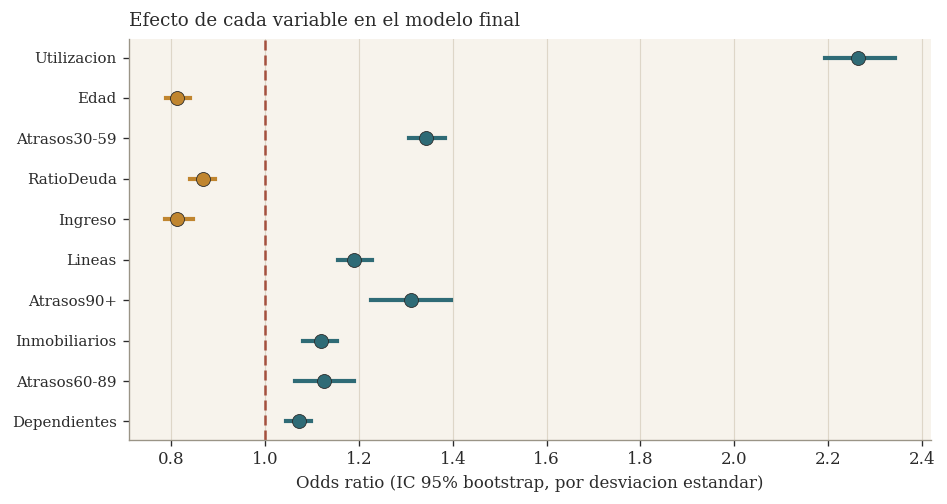

In [10]:
fig,ax=plt.subplots(figsize=(8,4.3))
rr=[r for r in rows if r[0]!='const']; yy=np.arange(len(rr))[::-1]
for r,yv in zip(rr,yy):
    orr,lo,hi=r[6],r[7],r[8]; col=TEAL if orr>1 else OCHRE
    ax.plot([lo,hi],[yv,yv],color=col,lw=2.5,zorder=2); ax.scatter(orr,yv,color=col,s=70,edgecolor=INK,lw=0.5,zorder=3)
ax.axvline(1,color=BRICK,ls=(0,(4,2)),lw=1.5,zorder=1)
ax.set_yticks(yy); ax.set_yticklabels([r[0] for r in rr],fontsize=9)
ax.set_xlabel('Odds ratio (IC 95% bootstrap, por desviacion estandar)'); ax.set_title('Efecto de cada variable en el modelo final')
ax.set_axisbelow(True); ax.grid(axis='x',color=GRIDC,lw=0.7); ax.grid(axis='y',visible=False)
plt.tight_layout(); plt.savefig('fig_bootstrap_or.png',bbox_inches='tight'); plt.show()

Todos los odds ratios son estables, ningún IC bootstrap cruza el 1 y son casi idénticos a los de Wald, en coeficientes y en odds ratios. La coincidencia no es casual, es decir, con más de 100.000 observaciones la normalidad asintótica del estimador de máxima verosimilitud ya se sostiene, así que Wald y bootstrap convergen. La utilización es el mayor factor de riesgo, edad e ingreso protegen. No hay parámetros inestables.

### 2.4 Diagnóstico de supuestos

In [11]:
Xv=Xtr_s[:,idxb]
vif=pd.DataFrame({'Variable':[short[FEATURES[i]] for i in idxb],'VIF':[variance_inflation_factor(Xv,i) for i in range(len(idxb))]}).set_index('Variable')
print(vif.round(2))
base=sm_fit.predict(sm.add_constant(Xtr_s[:,idxb])); pr=(ytr-base)/np.sqrt(base*(1-base))
print(f'\nResiduos de Pearson |r|>3: {int(np.sum(np.abs(pr)>3)):,} de {len(pr):,} ({np.mean(np.abs(pr)>3)*100:.2f}%)')

                VIF
Variable           
Utilizacion    1.17
Edad           1.16
Atrasos30-59   1.83
RatioDeuda     1.33
Ingreso        1.46
Lineas         1.32
Atrasos90+     2.55
Inmobiliarios  1.40
Atrasos60-89   2.69
Dependientes   1.12

Residuos de Pearson |r|>3: 2,448 de 104,999 (2.33%)


Los VIF son todos menores a 2,7 (los mayores en atrasos 60-89 y 90+). Esto confirma el hallazgo de S2: la colinealidad casi perfecta que sugería la correlación cruda de 0,98 era un artefacto de los códigos 96/98; ya acotados, no hay multicolinealidad y las tres variables de atrasos conviven en el modelo. Los residuos de Pearson extremos son pocos (2,3%).

#### Figura 3. Multicolinealidad (VIF)

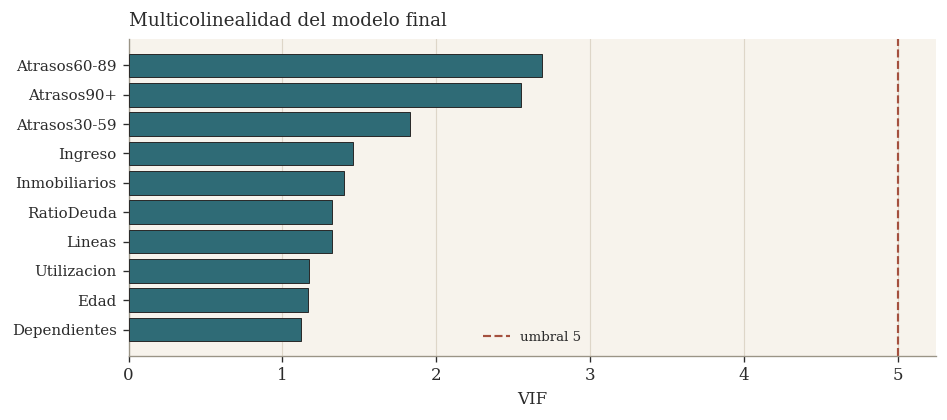

In [12]:
fig,ax=plt.subplots(figsize=(8,3.6)); vv=vif.sort_values('VIF')
ax.barh(range(len(vv)),vv['VIF'],color=TEAL,edgecolor=INK,lw=0.6,zorder=3); ax.axvline(5,color=BRICK,ls='--',lw=1.3,label='umbral 5',zorder=2)
ax.set_yticks(range(len(vv))); ax.set_yticklabels(vv.index,fontsize=9); ax.set_xlabel('VIF'); ax.set_title('Multicolinealidad del modelo final')
ax.set_axisbelow(True); ax.grid(axis='x',color=GRIDC,lw=0.7); ax.grid(axis='y',visible=False); ax.legend(fontsize=8,frameon=False)
plt.tight_layout(); plt.savefig('fig_vif.png',bbox_inches='tight'); plt.show()

### 2.5 Evaluación de desempeño predictivo (entrenamiento y prueba)

In [13]:
cm_tr=confusion_matrix(ytr,best['yhat_tr']); cm_te=confusion_matrix(yte,best['yhat'])
print('Matriz de confusion - ENTRENAMIENTO\n', cm_tr, f"\n  acc={accuracy_score(ytr,best['yhat_tr']):.3f} recall={recall_score(ytr,best['yhat_tr']):.3f} prec={precision_score(ytr,best['yhat_tr']):.3f}")
print('Matriz de confusion - PRUEBA\n', cm_te, f"\n  acc={accuracy_score(yte,best['yhat']):.3f} recall={recall_score(yte,best['yhat']):.3f} prec={precision_score(yte,best['yhat']):.3f}")

Matriz de confusion - ENTRENAMIENTO
 [[78185 19796]
 [ 1794  5224]] 
  acc=0.794 recall=0.744 prec=0.209
Matriz de confusion - PRUEBA
 [[33738  8254]
 [  748  2260]] 
  acc=0.800 recall=0.751 prec=0.215


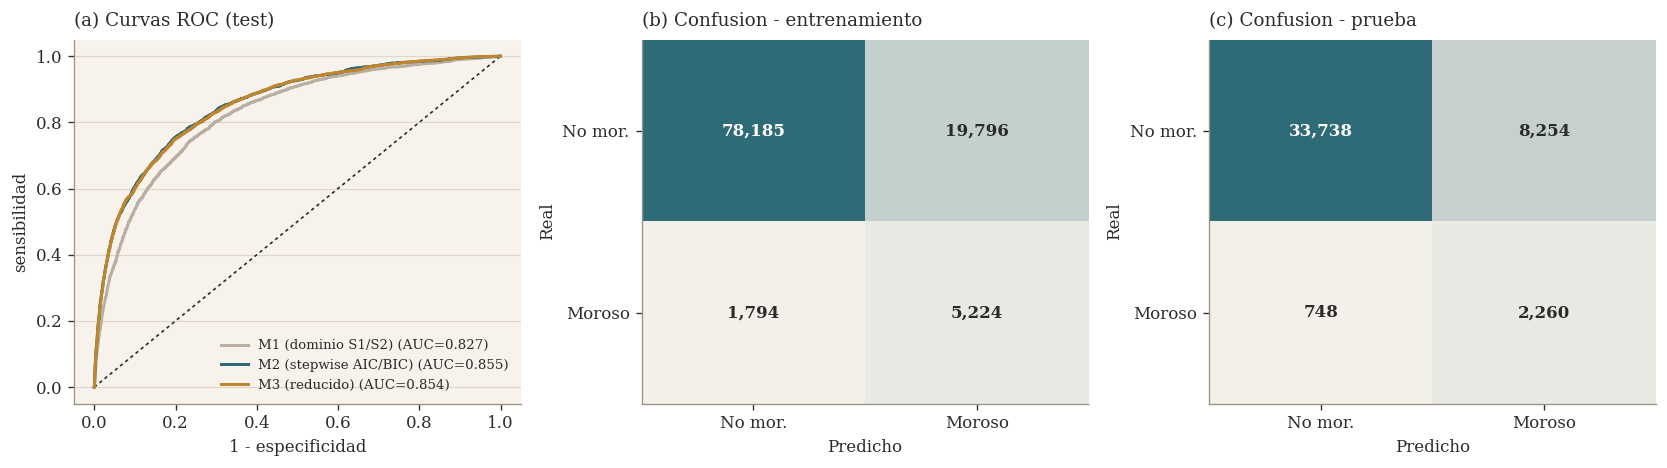

In [14]:
from matplotlib.colors import LinearSegmentedColormap
cm_editorial = LinearSegmentedColormap.from_list('cm_editorial', [PANEL, TEAL])

fig,ax=plt.subplots(1,3,figsize=(14,4))
for M,c in [(M1,STEM),(M2,TEAL),(M3,OCHRE)]:
    fpr,tpr,_=roc_curve(yte,M['pte']); ax[0].plot(fpr,tpr,color=c,lw=1.8,label=f"{M['name']} (AUC={M['auc']:.3f})",zorder=3)
ax[0].plot([0,1],[0,1],color=INK,ls=(0,(2,2)),lw=1,zorder=2)
ax[0].set_title('(a) Curvas ROC (test)'); ax[0].set_xlabel('1 - especificidad'); ax[0].set_ylabel('sensibilidad'); grid_h(ax[0]); ax[0].legend(fontsize=8,frameon=False,loc='lower right')
for a,cm,tt in [(ax[1],cm_tr,'(b) Confusion - entrenamiento'),(ax[2],cm_te,'(c) Confusion - prueba')]:
    vmax=cm.max()
    a.imshow(cm,cmap=cm_editorial,aspect='auto',vmin=0,vmax=vmax)
    for (i,j),v in np.ndenumerate(cm):
        txt_color='white' if v/vmax>0.55 else INK
        a.text(j,i,f'{v:,}',ha='center',va='center',color=txt_color,fontsize=10,fontweight='bold')
    a.set_xticks([0,1]); a.set_xticklabels(['No mor.','Moroso']); a.set_yticks([0,1]); a.set_yticklabels(['No mor.','Moroso'])
    a.set_xlabel('Predicho'); a.set_ylabel('Real'); a.set_title(tt); a.grid(False)
plt.tight_layout(); plt.savefig('fig_desempeno.png',bbox_inches='tight'); plt.show()

El modelo final alcanza AUC 0,855 en prueba (0,854 en entrenamiento: sin sobreajuste), superior al parsimonioso (0,828). Con umbral 0,5 y ponderación por clase recupera el 75% de los morosos a costa de precisión baja (0,21), lo esperable con tasa base de 6,7%: prioriza no dejar pasar morosos, criterio adecuado en crédito. El AUC, insensible al umbral, resume mejor la discriminación que la accuracy, engañosa por el desbalance.

## 3. Análisis comparativo del impacto de la imputación
Ajustamos el modelo final con los tres conjuntos y comparamos tamaño, AUC y el vector de coeficientes con sus intervalos de confianza (no solo el ingreso), para ver si la eliminación desplaza otros coeficientes por cambio de composición muestral.

In [15]:
keyv=['RevolvingUtilizationOfUnsecuredLines',D1,'MonthlyIncome']; keyn=['Utilizacion','Atrasos30-59','Ingreso']
rows=[]
for nm,d in [('Eliminacion',df_del),('Imputacion simple',df_simple),('Imputacion regresion',df_reg)]:
    Xa=d[FEATURES].values; ya=d[TARGET].values
    Xa_tr,Xa_te,ya_tr,ya_te=train_test_split(Xa,ya,test_size=0.30,random_state=SEED,stratify=ya)
    sca=StandardScaler().fit(Xa_tr); smf=sm.Logit(ya_tr,sm.add_constant(sca.transform(Xa_tr))).fit(disp=0,maxiter=300); ci=smf.conf_int()
    au=roc_auc_score(ya_te, LogisticRegression(penalty=None,max_iter=2000,class_weight='balanced').fit(sca.transform(Xa_tr),ya_tr).predict_proba(sca.transform(Xa_te))[:,1])
    r=[nm,len(ya_te),round(au,3)]
    for kv in keyv:
        j=FEATURES.index(kv)+1; r.append(f'{smf.params[j]:+.3f} [{ci[j,0]:+.3f}, {ci[j,1]:+.3f}]')
    rows.append(r)
print(pd.DataFrame(rows,columns=['Estrategia','n_test','AUC']+[f'coef {n}' for n in keyn]).set_index('Estrategia').to_string())

                      n_test    AUC         coef Utilizacion        coef Atrasos30-59             coef Ingreso
Estrategia                                                                                                    
Eliminacion            36081  0.842  +0.761 [+0.730, +0.792]  +0.316 [+0.292, +0.339]  -0.226 [-0.264, -0.188]
Imputacion simple      45000  0.855  +0.817 [+0.789, +0.845]  +0.294 [+0.271, +0.317]  -0.177 [-0.209, -0.145]
Imputacion regresion   45000  0.855  +0.817 [+0.789, +0.844]  +0.294 [+0.272, +0.317]  -0.208 [-0.244, -0.172]


El AUC casi no cambia (0,842 a 0,855). Los coeficientes de utilización y atrasos son estables entre las tres estrategias (sus IC se solapan), la señal fuerte no depende de la imputación. El único que se mueve es el del ingreso, de -0,18 (regresión) a -0,23 (eliminación). Al descartar 30.000 casos, la eliminación cambia la composición muestral y desplaza el coeficiente del predictor más débil, aunque sin alterar las conclusiones. Es el riesgo que la eliminación introduce y que la imputación evita.

## 4. Síntesis integrada e informe final

**Resumen ejecutivo.** Modelo de clasificación de riesgo crediticio con AUC 0,855, estable y sin multicolinealidad. El riesgo sube con la utilización de crédito y el historial de atrasos, y baja con la edad y el ingreso.

**Metodología integrada (S1 -> S2 -> S3).** S1 caracterizó el problema (desbalance, faltantes, outliers, códigos, señales). S2 validó con remuestreo y corrigió el artefacto de la correlación de atrasos. S3 imputó el ingreso, seleccionó variables con tres criterios, confirmó con VIF la ausencia de colinealidad y validó la estabilidad con bootstrap.

**Discusión.** Tres limitaciones que quedan abiertas: (1) la imputación por regresión encoge la varianza del ingreso un 86%, y una imputación múltiple la restauraría; (2) el coeficiente del ingreso se mueve 25% entre estrategias, señal de fragilidad de un predictor débil; (3) a este tamaño muestral AIC, BIC y la validación cruzada no distinguen el modelo completo del reducido, así que la selección automática aporta poco frente al juicio informado por S1/S2.

**Conclusiones.** El modelo sirve para apoyar decisiones si el umbral se calibra según el costo de falsos negativos y positivos; se recomienda operar por probabilidad de riesgo, priorizar utilización y atrasos, y monitorear la estabilidad. Como trabajo futuro, modelos no lineales podrían aprovechar las relaciones no lineales que S1 insinuó.

In [16]:
print('Figuras:', sorted(f for f in os.listdir('.') if f.startswith('fig_') and f.endswith('.png')))

Figuras: ['fig_bootstrap_or.png', 'fig_desempeno.png', 'fig_imputacion.png', 'fig_vif.png']
